Paquetes necesarios

In [1]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv
import math 

Carga imagen ideal con monedas y convierte a RGB

In [3]:
#Carga imagen ejemplo con monedas
img = cv2.imread('Monedas.jpg') 
print(img.shape)
#Recordar que OpenCV lee las imágenes en BGR, por lo que convertimos para visualizr a RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

(938, 473, 3)


TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaría en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y milímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



In [ ]:
img = cv2.imread('Monedas.jpg')

coin_size = {
    2.0: 25.75, 
    1.0: 23.25,
    0.50: 24.25,
    0.20: 22.25,
    0.10: 19.75,
    0.05: 21.25,
    0.02: 18.75,
    0.01: 16.25
}

gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
pimg = cv2.medianBlur(gris, 3)

# Localiza Círculos
circ = cv2.HoughCircles(
        pimg,   
        cv2.HOUGH_GRADIENT,  
        1,
        100,  
        param1=140, 
        param2=50, 
        minRadius=30,  
        maxRadius=150,  
    )

print(circ)


# Contornos de las monedas: fondo blanco -> todo lo que sea más oscuro es moneda
# (se hace ANTES de dibujar nada sobre img)
mask = cv2.threshold(gris, 200, 255, cv2.THRESH_BINARY_INV)[1]
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
contornos, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)


def measure_diameter(x, y, radius):
    # Busca el contorno que contiene el centro del círculo de Hough
    # y devuelve su diámetro a partir del área (mucho más preciso que el radio de Hough)
    for c in contornos:
        if cv2.pointPolygonTest(c, (float(x), float(y)), False) >= 0:
            area = cv2.contourArea(c)
            return math.sqrt(4 * area / math.pi)
    return radius * 2   # si no encuentra contorno, usa el de Hough



def calibrate_coin():
    print("Haz click en la moneda de 1€")

    for i in circ[0, :]:
        center_x = int(i[0])
        center_y = int(i[1])
        radius = int(i[2])

        cv2.circle(img, (center_x, center_y), radius, (0, 255, 0), 2) # Borde
        cv2.circle(img, (center_x, center_y), 2, (0,0,255), 3)  # Centro

cv2.imwrite('img/tarea1_1_hough.jpg', img)

def search_clicked_coin(clic_x, clic_y):

    for i in circ[0, :]:
        center_x = int(i[0])
        center_y = int(i[1])
        radius = int(i[2])

        # teorema pitagoras 
        distance = math.sqrt(((clic_x - center_x)**2) + ((clic_y - center_y)**2))

        if (distance < radius):
            # Estamos dentro del area de la moneda
            diameter = measure_diameter(center_x, center_y, radius)
            # Obtenemos la relacion (mm/pixel)
            global pix_to_mm
            pix_to_mm = coin_size[1.0] / diameter

            print(f"La moneda de 1€ que clicaste, tiene diámetro: {diameter}px")
            print(f"La imagen tiene una relación pix/mm de {pix_to_mm}")

            count_money(pix_to_mm)

            break

        
def click_calibration(event, x, y, flags, param):

    if (event == cv2.EVENT_LBUTTONDOWN):    # Si le damos click izq
        print(f"Clic detectado en: {x}, {y}")

        search_clicked_coin(x, y)


def count_money(size_mm_pixel):

    total = 0
    
    for i in circ[0, :]:
        radius = int(i[2])

        diameter = measure_diameter(i[0], i[1], radius)
        diameter_mm = diameter * size_mm_pixel
        
        print(f"He detectado un círculo que mide {diameter_mm:.2f} mm")

        min_diference = 1000 # margen de error
        coin_value = 0
        
        for value, real_size in coin_size.items():

            diference = abs(diameter_mm - real_size)

            if diference < min_diference:
                min_diference = diference
                coin_value = value
                
        total += coin_value

        print(f"Detectada moneda de: {coin_value}€")

        # Escribe el valor sobre la moneda (con contorno blanco para que se lea bien)
        pos = (int(i[0]) - 28, int(i[1]) + 8)
        cv2.putText(img, f"{coin_value:.2f}", pos, cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 5)
        cv2.putText(img, f"{coin_value:.2f}", pos, cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)

    print(f"TOTAL DE DINERO: {total:.2f}€")

    cv2.putText(img, f"TOTAL: {total:.2f} EUR", (265, 24),
    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
    cv2.imshow("Calibrar", img)
    cv2.imwrite('img/tarea1_2_salida_final.png', img)


calibrate_coin()

cv2.namedWindow("Calibrar")
cv2.setMouseCallback("Calibrar", click_calibration)
cv2.imshow("Calibrar", img)

cv2.waitKey(0)
cv2.destroyAllWindows()
cv2.waitKey(1)

Demostrador en vivo

In [ ]:
coin_size = {
    2.0: 25.75,
    1.0: 23.25,
    0.50: 24.25,
    0.20: 22.25,
    0.10: 19.75,
    0.05: 21.25,
    0.02: 18.75,
    0.01: 16.25
}

pix_to_mm = 0
circ = None
contornos = []
reference_coin_pos = []
calibrated = False


def measure_diameter(x, y, radius):
    # Busca el contorno que contiene el centro del círculo de Hough
    # y devuelve su diámetro a partir del área (mucho más preciso que el radio de Hough)
    for c in contornos:
        if cv2.pointPolygonTest(c, (float(x), float(y)), False) >= 0:
            area = cv2.contourArea(c)
            return math.sqrt(4 * area / math.pi)
    return radius * 2   # si no encuentra contorno, usa el de Hough

def distance_to_reference(point):
    return math.sqrt((point[0] - reference_coin_pos[0])**2 + (point[1] - reference_coin_pos[1])**2)

def search_clicked_coin(clic_x, clic_y):
    for i in circ[0, :]:
        center_x = int(i[0])
        center_y = int(i[1])
        radius = int(i[2])

        # teorema pitagoras
        distance = math.sqrt(((clic_x - center_x)**2) + ((clic_y - center_y)**2))

        if (distance < radius):
            # Estamos dentro del area de la moneda
            #diameter = measure_diameter(center_x, center_y, radius)
            diameter = radius * 2
            # Obtenemos la relacion (mm/pixel)
            global pix_to_mm
            pix_to_mm = coin_size[1.0] / diameter

            print(f"La moneda de 1€ que clicaste, tiene diámetro: {diameter}px")
            print(f"La imagen tiene una relación pix/mm de {pix_to_mm}")

            reference_coin_pos = [center_x, center_y]
            calibrated = True
            count_money(pix_to_mm)

            break

def click_calibration(event, x, y, flags, param):

    if (event == cv2.EVENT_LBUTTONDOWN):    # Si le damos click izq
        print(f"Clic detectado en: {x}, {y}")

        search_clicked_coin(x, y)

# Devuelve el radio de un circulo que se asemeje una elipse dada
def radii_from_ellipse(ellipse):
    return (ellipse[1][0] + ellipse[1][1]) / 4


def count_money(size_mm_pixel):
    total = 0
    if circ is not None:
        for i in circ[0, :]:
            radius = int(i[2])

            #diameter = measure_diameter(i[0], i[1], radius)
            diameter = radius * 2
            diameter_mm = diameter * size_mm_pixel

            min_diference = 1000 # margen de error
            coin_value = 0
            
            for value, real_size in coin_size.items():

                diference = abs(diameter_mm - real_size)

                if diference < min_diference:
                    min_diference = diference
                    coin_value = value
            total += coin_value

    return total

cap = cv2.VideoCapture(0)
#cap = cv2.VideoCapture("http://192.168.0.30:8081/video")

cv2.namedWindow("Demostrador")
cv2.setMouseCallback("Demostrador", click_calibration)

print("Enfoca las monedas. Haz click en la moneda de 1€ para iniciar el conteo.")

while True:
    ret, frame = cap.read()
    if not ret:
        break
    
    frame = cv2.flip(frame, 1)
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    pimg = cv2.medianBlur(gris, 5)

    # Contorno para delimitar el fondo
    mask_fondo = cv2.threshold(pimg, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    #mask_fondo = cv2.adaptiveThreshold(pimg, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 3, 3)[1]
    contornos = cv2.findContours(mask_fondo, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]

    mask_fondo = np.zeros(frame.shape[:2], dtype="uint8")
    
    # Hallamos el mayor contorno donde se pondrá la zona de detección
    areas = list(map(cv2.contourArea, contornos))
    if len(areas) > 1:
        max_contour = contornos[areas.index(max(areas))]

        epsilon = 0.1 * cv2.arcLength(max_contour, True)
        contorno_fondo = cv2.approxPolyDP(max_contour, epsilon, True)
        cv2.drawContours(mask_fondo, [contorno_fondo], 0, (255, 255, 255), -1)
        cv2.drawContours(mask_fondo, [contorno_fondo], 0, (0, 0, 0), 20)

    # Contornos de las monedas: folio blanco -> todo lo que sea más oscuro es moneda
    # (se hace con 'gris', antes de dibujar nada sobre el fotograma)
    mask = cv2.threshold(pimg, 200, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    mask = cv2.bitwise_and(mask, mask, mask=mask_fondo)
    mask = cv2.GaussianBlur(mask, (5, 5), 0)

    # Se hallan las monedas
    contornos_monedas = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]
    coins = []
    for c in contornos_monedas:
        if len(c) < 5:
            continue
        ellipse = cv2.fitEllipse(c);
        if abs(ellipse[1][0] - ellipse[1][1]) > 20:
            continue
        if math.pi / 4 * ellipse[1][0] * ellipse[1][1] < 200:
            continue
        cv2.ellipse(frame, ellipse, (255, 20, 10), 3)
        cv2.circle(frame, list(map(int, ellipse[0])), 2, (0,0,255), 3)
        coins.append([ellipse[0][0], ellipse[0][1], radii_from_ellipse(ellipse)])

    circ = np.array([coins])

    if calibrated:
        dists = list(map(distance_to_reference, coins))
        new_ref = coins[dists.index(min(dists))]
        pix_to_mm = coin_size[1.0] / (new_ref[2] * 2)
        reference_coin_pos = [new_ref[0], new_ref[1]]

    # Si ya hemos hecho click y tenemos la relación, calculamos el dinero
    if pix_to_mm > 0:
        total_money = count_money(pix_to_mm)
        cv2.putText(frame, f"TOTAL: {total_money:.2f} Euros", (20, 50),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2, cv2.LINE_AA)
    else:
        cv2.putText(frame, "Haz click en la moneda de 1 Euro", (20, 50),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2, cv2.LINE_AA)

    cv2.imshow("Demostrador", frame)

    if cv2.waitKey(20)  == 27:
        break

cap.release()
cv2.destroyAllWindows()
cv2.waitKey(1)

TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

clases = ['FRA', 'PEL', 'TAR']

# Mismos colores (BGR) que en la celda de anotaciones
colores = {
    "FRA": (0, 0, 255),   # Rojo
    "PEL": (0, 255, 0),   # Verde
    "TAR": (255, 0, 0)    # Azul
}

In [10]:
# Segmentación 
def segmentar(imagen):
    """Devuelve los contornos externos de las partículas de una imagen BGR."""
    imagen = cv2.GaussianBlur(imagen, (5, 5), 0)

    # Estimamos el fondo con una mediana muy grande (sobre la imagen reducida):
    # así se compensa que la luz no sea uniforme y las partículas no cuentan como fondo.
    peq = cv2.resize(imagen, None, fx=0.1, fy=0.1, interpolation=cv2.INTER_AREA)
    fondo = cv2.medianBlur(peq, 31)
    fondo = cv2.resize(fondo, (imagen.shape[1], imagen.shape[0]))

    # Partícula = lo que se diferencia del fondo (más clara, más oscura o de otro color).
    # Nos quedamos con la mayor diferencia entre los tres canales de color.
    dif = cv2.absdiff(imagen, fondo).max(axis=2)

    # Umbral de Otsu, pero sin dejar que suba de 25 (para no perder las partículas claras)
    umbral_otsu, _ = cv2.threshold(dif, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    umbral = max(10, min(umbral_otsu, 25))
    _, imth = cv2.threshold(dif, umbral, 255, cv2.THRESH_BINARY)

    # Limpieza: quita motas y cierra huecos pequeños
    imth = cv2.morphologyEx(imth, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    imth = cv2.morphologyEx(imth, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))

    # Obtiene únicamente los contornos externos
    contornos, hierarchy = cv2.findContours(imth, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    # Descarta lo muy pequeño (ruido)
    return [c for c in contornos if cv2.contourArea(c) > 100]

In [12]:
# Características de cada partícula 
def caracteristicas(c, gris, sat):
    area = cv2.contourArea(c)
    perimetro = cv2.arcLength(c, True)
    compacidad = perimetro ** 2 / area

    # rectángulo de área mínima y elipse ajustada
    _, (rw, rh), _ = cv2.minAreaRect(c)
    rel_area_contenedor = area / (rw * rh)
    rel_ancho_alto = min(rw, rh) / max(rw, rh)
    _, (e1, e2), _ = cv2.fitEllipse(c)
    rel_elipse = min(e1, e2) / max(e1, e2)

    # Distancias del centroide al contorno
    M = cv2.moments(c)
    cx, cy = M['m10'] / M['m00'], M['m01'] / M['m00']
    d = np.sqrt((c[:, 0, 0] - cx) ** 2 + (c[:, 0, 1] - cy) ** 2)
    rel_dist = d.min() / d.max()

    # brillo y saturación medios dentro de la partícula
    mascara = np.zeros(gris.shape, np.uint8)
    cv2.drawContours(mascara, [c], -1, 255, -1)
    brillo = cv2.mean(gris, mask=mascara)[0]
    saturacion = cv2.mean(sat, mask=mascara)[0]

    return [area, perimetro, compacidad, rel_area_contenedor,
            rel_ancho_alto, rel_elipse, rel_dist, brillo, saturacion], (cx, cy)


def extraer(imagen):
    """Segmenta la imagen y devuelve características, contornos y centroides."""
    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
    sat = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)[:, :, 1]
    contornos = segmentar(imagen)
    feats, centros = [], []
    for c in contornos:
        f, centro = caracteristicas(c, gris, sat)
        feats.append(f)
        centros.append(centro)
    return np.array(feats), contornos, centros

FRA : 11 partículas
PEL : 11 partículas
TAR : 8 partículas


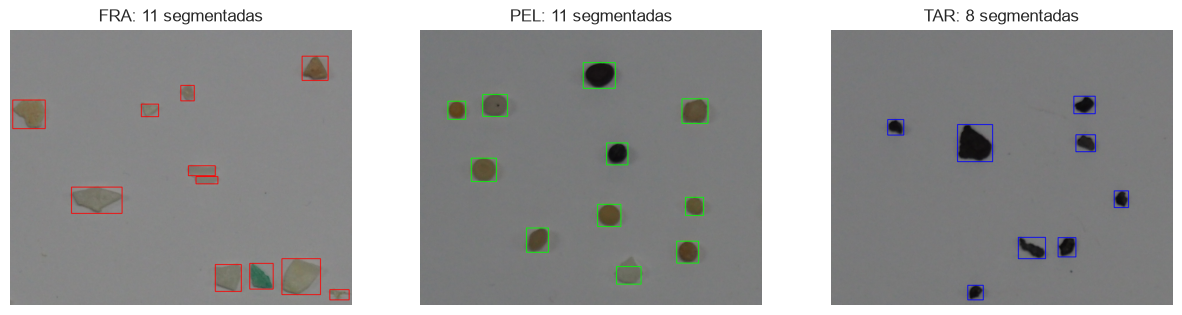

In [21]:
# Entrenamiento: guardar las características de las muestras de cada clase
X_train, y_train = [], []

plt.figure(figsize=(15, 5))

for idx, clase in enumerate(clases):
    # Carga imagen original
    img_bgr = cv2.imread(clase + '.png')
    
    # Extrae características y contornos
    feats, contornos, centros = extraer(img_bgr)
    
    X_train.append(feats)
    y_train += [clase] * len(feats)
    print(clase, ':', len(feats), 'partículas')
    
    # Copia de la imagen para dibujar encima
    img_draw = img_bgr.copy()
    for c in contornos:
        # Contenedor alineado con los ejes
        x, y, w, h = cv2.boundingRect(c)
        # Dibujamos rectángulo con el color de la clase
        cv2.rectangle(img_draw, (x, y), (x+w, y+h), colores[clase], 2)
        
    # Añadimos al subplot (1 fila, 3 columnas)
    plt.subplot(1, 3, idx+1)
    plt.imshow(cv2.cvtColor(img_draw, cv2.COLOR_BGR2RGB))
    plt.title(f"{clase}: {len(feats)} segmentadas")
    plt.axis('off')

X_train = np.vstack(X_train)
y_train = np.array(y_train)

# Normalizamos
media = X_train.mean(axis=0)
desviacion = X_train.std(axis=0) + 1e-9
Xn = (X_train - media) / desviacion

def clasificar(vector, k=3):
    v = (vector - media) / desviacion
    distancias = np.linalg.norm(Xn - v, axis=1)
    vecinos = y_train[np.argsort(distancias)[:k]]
    valores, cuentas = np.unique(vecinos, return_counts=True)
    return valores[np.argmax(cuentas)]

# GUARDAR LA IMAGEN 
plt.savefig("img/tarea2_1_entrenamiento.jpg", bbox_inches='tight', dpi=300)
plt.show()

Partículas segmentadas en test: 90
Anotaciones sin partícula segmentada: 15


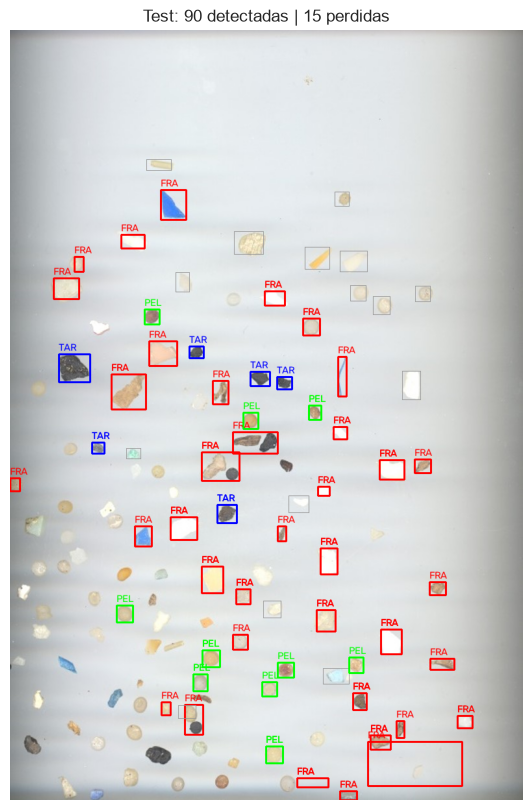

In [22]:
# clasificar MPs_test.jpg y comparar con las anotaciones 
img_test = cv2.imread("MPs_test.jpg")
feats_test, contornos_test, centros_test = extraer(img_test)
print('Partículas segmentadas en test:', len(feats_test))

y_real, y_pred, usados = [], [], []
sin_detectar = 0

img_resultado = img_test.copy()

with open("MPs_test_bbs.csv", newline="") as file:
    for row in csv.DictReader(file):
        x_min, y_min, x_max, y_max = map(int, [row["x_min"], row["y_min"], row["x_max"], row["y_max"]])
        
        dentro = [i for i, (cx, cy) in enumerate(centros_test)
                  if x_min <= cx <= y_max and y_min <= cy <= y_max]
        if len(dentro) == 0:
            sin_detectar += 1
            # Dibujamos en gris las cajas que NO detectó el algoritmo (para evidenciar el fallo)
            cv2.rectangle(img_resultado, (x_min, y_min), (x_max, y_max), (150, 150, 150), 1)
            continue
            
        i = max(dentro, key=lambda i: cv2.contourArea(contornos_test[i]))
        clase_real = row["label"]
        clase_predicha = clasificar(feats_test[i])
        
        y_real.append(clase_real)
        y_pred.append(clase_predicha)
        usados.append(i)
        
        # Dibujamos la caja predicha usando el color correspondiente a esa clase
        color = colores.get(clase_predicha, (255, 255, 255))
        x, y, w, h = cv2.boundingRect(contornos_test[i])
        cv2.rectangle(img_resultado, (x, y), (x+w, y+h), color, 2)
        # Ponemos el texto de lo que adivinó
        cv2.putText(img_resultado, clase_predicha, (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

print('Anotaciones sin partícula segmentada:', sin_detectar)

# VISUALIZAR Y GUARDAR 
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(img_resultado, cv2.COLOR_BGR2RGB))
plt.title(f"Test: {len(feats_test)} detectadas | {sin_detectar} perdidas")
plt.axis('off')

# Guardamos en la carpeta img
plt.savefig("img/tarea2_2_test_segmentado.jpg", bbox_inches='tight', dpi=300)
plt.show()

Accuracy (TP/(n))= 0.7857142857142857
Precision (TP/(TP+FP)) = 0.7982692135234508
Recall (TP/(TP+FN)) = 0.7857142857142857
F1 Score (2*(precision*recall)/(precision+recall)) = 0.776291155936885


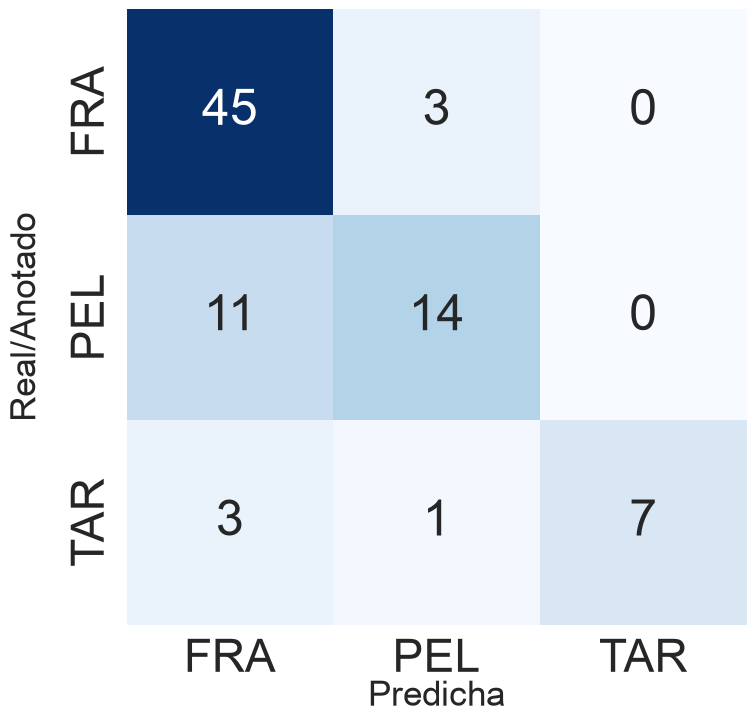

In [20]:
# Métricas y matriz de confusión 
accuracy = accuracy_score(y_real, y_pred)
precision = precision_score(y_real, y_pred, average='weighted')
recall = recall_score(y_real, y_pred, average='weighted')
f1score = f1_score(y_real, y_pred, average='weighted')

print(f"Accuracy (TP/(n))= {accuracy}")
print(f"Precision (TP/(TP+FP)) = {precision}")
print(f"Recall (TP/(TP+FN)) = {recall}")
print(f"F1 Score (2*(precision*recall)/(precision+recall)) = {f1score}")
conf_matrix = confusion_matrix(y_real, y_pred, labels=clases)
plt.figure(figsize=(8, 8))
sns.set(font_scale=3.0)
ax = sns.heatmap(conf_matrix, annot=True, fmt='d', cbar=False, cmap='Blues',
                 xticklabels=clases, yticklabels=clases)
label_font = {'size': '25'}
ax.set_xlabel("Predicha", labelpad=-0.75, fontdict=label_font)
ax.set_ylabel("Real/Anotado", labelpad=20, fontdict=label_font)
plt.savefig('img/tarea2_2.jpg', bbox_inches='tight', dpi=300)
plt.show()
sns.set(font_scale=1.0)

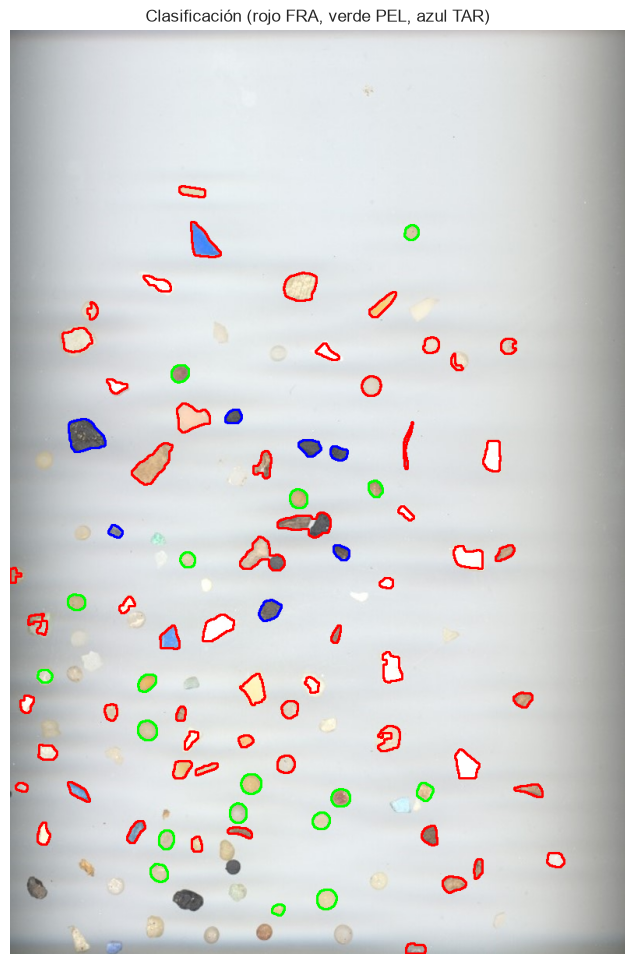

In [19]:
# Resultado sobre la imagen 
for i, p in zip(usados, y_pred):
    cv2.drawContours(img_test, [contornos_test[i]], -1, colores[p], 2)
plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(img_test, cv2.COLOR_BGR2RGB))
cv2.imwrite('img/tarea2_1.jpg', img_test)
plt.title("Clasificación (rojo FRA, verde PEL, azul TAR)")
plt.axis('off')
plt.show()